# 6 · Trade studies

Lesson: [06](../docs/lessons/06-trade-studies.md) · Theory: [trade studies](../docs/trade_studies.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from propulsion import plotting as P
from propulsion.flight import FlightCondition
from propulsion.units import FT, tsfc_to_lb_per_lbf_h

P.use_style()
np.set_printoptions(precision=4, suppress=True)
FL350 = FlightCondition.at_altitude(35000 * FT, 0.78, geopotential=True)
SLS = FlightCondition.sea_level_static()
sys.path.insert(0, "../validation")  # calibrated engine models and cited data
from engines import calibrated_engine, ENGINES
from reference import icao, tcds, LTO_MODES
from engines import ENGINE_COMPONENTS
from propulsion.trade_studies import sweep, fan_diameter
from propulsion.turbofan_model import turbofan
KW = dict(components=ENGINE_COMPONENTS, core_nozzle="convergent", fan_nozzle="convergent",
          pi_cL=1.6, pi_f_max=10.0)

## Cruise TSFC vs bypass ratio, each point with its best fan

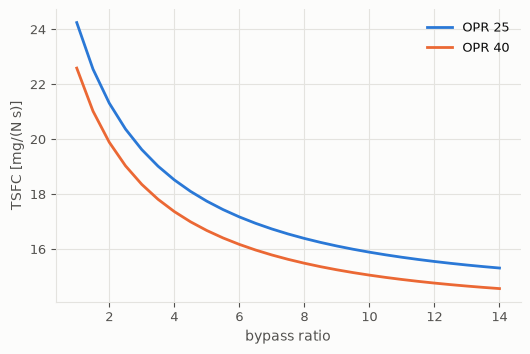

In [2]:
alpha = np.linspace(1.0, 14.0, 27)
fig, ax = plt.subplots(figsize=(6, 3.8))
for opr in (25.0, 40.0):
    s = sweep(FL350, alpha, opr, 1300.0, **KW)
    ax.plot(alpha, s.tsfc[:, 0, 0] * 1e6, label=f"OPR {opr:.0f}")
ax.set_xlabel("bypass ratio"); ax.set_ylabel("TSFC [mg/(N s)]"); ax.legend(); plt.show()

## The price of bypass at 120 kN take-off thrust

In [3]:
for a in (1.0, 5.0, 9.0, 13.0):
    s = sweep(SLS, a, 35.0, 1450.0, **KW)
    mdot = 120e3 / s.specific_thrust.item()
    print(f"alpha {a:4.1f}: best fan {s.pi_f.item():.2f}, airflow {mdot:5.0f} kg/s, "
          f"fan diameter {float(fan_diameter(mdot, SLS)):.2f} m")

alpha  1.0: best fan 4.13, airflow   198 kg/s, fan diameter 1.17 m
alpha  5.0: best fan 1.83, airflow   353 kg/s, fan diameter 1.56 m
alpha  9.0: best fan 1.46, airflow   463 kg/s, fan diameter 1.79 m
alpha 13.0: best fan 1.32, airflow   554 kg/s, fan diameter 1.95 m


## The NOx price of pressure ratio (ICAO databank)

In [4]:
for name in ("CFM56-7B26/3", "CFM56-7B27/3", "LEAP-1B25", "LEAP-1B28"):
    Tt3 = float(calibrated_engine(name).design_point.cycle.stations["3"].T)
    d = icao(name)
    print(f"{name:13s} OPR {d['opr']:5.1f}  model Tt3 {Tt3:5.0f} K  NOx EI {d['nox_takeoff']:5.1f} g/kg  "
          f"({d['combustor']})")

CFM56-7B26/3  OPR  27.7  model Tt3   808 K  NOx EI  21.8 g/kg  (Tech Insertion)
CFM56-7B27/3  OPR  29.0  model Tt3   820 K  NOx EI  23.9 g/kg  (Tech Insertion)
LEAP-1B25     OPR  39.1  model Tt3   899 K  NOx EI  48.2 g/kg  (TAPS II)
LEAP-1B28     OPR  42.0  model Tt3   920 K  NOx EI  72.8 g/kg  (TAPS II)
